# A tool-using agent from scratch: a walkthrough

This notebook follows the build in the order a tutorial would take it. Each section is a short
explanation, the few calls that show the idea, and their output.

| § | Stage | What it shows | Needs |
|---|---|---|---|
| 1 | 0.5 | one turn, one tool | a model |
| 2 | 1–2 | the agent loop over several calls, and a follow-up turn | a model |
| 3 | 3 | context management: a session compacted, what was kept, the session resumed | a model |
| 4 | 8 | evaluation: a generated task, the verifier, a correct run and two cheats | nothing |
| 5 | 9–10 | post-training: SFT, expert iteration and GRPO in one picture | nothing |
| 6 | 9 | SFT: a teacher model runs a train task, and its verified run becomes training examples | a model, the Qwen3 tokenizer |
| 7 | 10 | expert iteration and GRPO on the student's own recorded samples, and how they compared | nothing |

Sections 1–3 and 6 call a model. Sections 4, 5 and 7 need none: training itself needs a GPU, so
§7 works on recorded samples of the 4B student. Durable memory is not built yet (see the
roadmap in the README).

**Setup.** From the repository root: `pip install -r agent_from_scratch/requirements.txt jupyter
transformers`, then open this notebook. The first cell picks the model.

In [1]:
import json
import os
import sys
from pathlib import Path
from tempfile import mkdtemp
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm, imported by transformers
ROOT =next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "agent_from_scratch").is_dir())
sys.path.insert(0, str(ROOT))
DATA = ROOT / "agent_from_scratch/examples/data"

from loguru import logger
logger.remove()
logger.add(sys.stderr, level="WARNING")  # the agent logs every tool call at DEBUG

# The model. Any OpenAI-compatible chat API, chosen by environment variables, for example:
#   AGENT_BASE_URL=https://api.deepseek.com  AGENT_MODEL=deepseek-flash  AGENT_API_KEY=sk-...
#   AGENT_BASE_URL=https://api.openai.com/v1 AGENT_MODEL=<model ID>     AGENT_API_KEY=sk-...
#   AGENT_BASE_URL=http://localhost:11434/v1 AGENT_N_CTX=32768                     (Ollama)
#   AGENT_MODEL=hf.co/unsloth/Qwen3-4B-Instruct-2507-GGUF:Q4_K_M
# With AGENT_BASE_URL unset it is the local GGUF in config.MODEL_PATH (llama-cpp-python).
if not os.environ.get("AGENT_BASE_URL") and os.environ.get("DEEPSEEK_API_KEY"):
    os.environ.update(AGENT_BASE_URL="https://api.deepseek.com", AGENT_MODEL="deepseek-flash",
                      AGENT_API_KEY=os.environ["DEEPSEEK_API_KEY"])

from agent_from_scratch.llm import make_model

model = make_model()
print({k: v for k, v in model.settings().items() if k in ("backend", "base_url", "model", "model_path", "n_ctx")})


def cut(text, limit=150):
    text = " ".join(str(text).split())
    return text if len(text) <= limit else text[:limit] + " …"


def show(messages):
    # One line per message: the model's tool calls, the tools' results, and plain text.
    for m in messages:
        if m["role"] == "system":
            continue
        if m.get("tool_calls"):
            if m.get("content"):
                print(f"assistant : {cut(m['content'])}")
            for call in m["tool_calls"]:
                print(f"assistant → {call['function']['name']}({call['function']['arguments']})")
        elif m["role"] == "tool":
            result = json.loads(m["content"])
            output = result["output"] if result["ok"] else result["error_message"]
            if isinstance(output, dict):  # file tools return metadata too; the content is what matters here
                output = output.get("content", {k: v for k, v in output.items() if k != "version"})
            print(f"tool      ← {cut(output)}")
        elif m.get("content"):
            print(f"{m['role']:9} : {cut(m['content'])}")

{'backend': 'chat_api', 'base_url': 'https://api.deepseek.com', 'model': 'deepseek-flash', 'n_ctx': 32768}


## 1. One turn, one tool

A tool is a name, a description and a JSON schema for its arguments. The model sees the
schemas next to the conversation and may reply with a *tool call* instead of text. The harness
runs the call, appends the result as a `tool` message, and asks the model again. A reply with
no tool call ends the turn.

In [2]:
from agent_from_scratch.agent import Agent
from agent_from_scratch.tools.base import ToolRegistry
from agent_from_scratch.tools.calculator import CalculatorTool

calculator = ToolRegistry([CalculatorTool()])
print(json.dumps(calculator.schemas()["calculator"], indent=1))  # what the model is told

{
 "type": "function",
 "function": {
  "name": "calculator",
  "description": "A calculator that can evaluate mathematical expressions.",
  "parameters": {
   "type": "object",
   "properties": {
    "operation": {
     "type": "string",
     "enum": [
      "add",
      "subtract",
      "multiply",
      "divide"
     ],
     "description": "The mathematical operation to perform."
    },
    "left": {
     "type": "number",
     "description": "The left operand."
    },
    "right": {
     "type": "number",
     "description": "The right operand."
    }
   },
   "required": [
    "operation",
    "left",
    "right"
   ],
   "additionalProperties": false
  }
 }
}


In [3]:
agent = Agent(model, registry=calculator)
result = agent.run_turn("What is 1234 * 5678 + 91? Use the calculator.")
show(result.messages)
print("\nstop:", result.stop_reason, "| model requests:", len(result.model_requests))

user      : What is 1234 * 5678 + 91? Use the calculator.
assistant → calculator({"operation": "multiply", "left": 1234, "right": 5678})
tool      ← 7006652
assistant → calculator({"operation": "add", "left": 7006652, "right": 91})
tool      ← 7006743
assistant : 1234 × 5678 = 7,006,652; plus 91 = **7,006,743**

stop: final_response | model requests: 3


Each model request either calls tools or answers in text; the last one here answered. `result`
also records each request's input, token usage and status. That record is the trace that
sections 4–6 score and learn from.

## 2. The agent loop, and a follow-up turn

The loop in `Agent.run_turn` repeats the step above until the model answers in text. It is
bounded: at most `max_iterations` model calls and `max_tool_calls` tool calls per turn, and a
stop after the same failure three times in a row. Several calls in one reply form a batch, run
in order. File tools are confined to a workspace; a write may name the version it read
(`expected_version`) and is refused if the file changed since. A follow-up turn is the same
call with the conversation so far as `history`.

In [4]:
from agent_from_scratch.context import InstructionConfig
from agent_from_scratch.tools.files import ListFilesTool, ReadFileTool, WriteFileTool

workspace = Path(mkdtemp(prefix="walkthrough-")) / "workspace"
(workspace / "notes").mkdir(parents=True)
(workspace / "notes/standup.md").write_text("Standup: the build is green. Lunch order moves to Friday.\n")
(workspace / "notes/infra.md").write_text("Infra: the database server moves to rack B4 on 2026-11-03, room 214.\n")
(workspace / "notes/hiring.md").write_text("Hiring: two interviews next week.\n")

files = ToolRegistry([ListFilesTool(workspace, restrict_to_workspace=True),
                      ReadFileTool(workspace, restrict_to_workspace=True),
                      WriteFileTool(workspace, restrict_to_workspace=True)])
agent = Agent(model, registry=files, instruction_config=InstructionConfig(workspace=workspace))
first = agent.run_turn("Which file in notes/ says when the database server moves? "
                       "Write just that date to answer.txt.")
show(first.messages)
print("\nmodel requests:", len(first.model_requests), "| answer.txt:", (workspace / "answer.txt").read_text())

user      : Which file in notes/ says when the database server moves? Write just that date to answer.txt.
assistant : I'll look through the notes directory to find the file mentioning the database server move.
assistant → list_files({"path": "notes"})
tool      ← {'path': 'notes', 'entries': [{'name': 'hiring.md', 'type': 'file', 'size_bytes': 34}, {'name': 'infra.md', 'type': 'file', 'size_bytes': 69}, {'name' …
assistant → read_file({"path": "notes/infra.md"})
assistant → read_file({"path": "notes/standup.md"})
assistant → read_file({"path": "notes/hiring.md"})
tool      ← 1| Infra: the database server moves to rack B4 on 2026-11-03, room 214.
tool      ← 1| Standup: the build is green. Lunch order moves to Friday.
tool      ← 1| Hiring: two interviews next week.
assistant → write_file({"path": "answer.txt", "content": "2026-11-03\n"})
tool      ← {'path': 'answer.txt', 'bytes_written': 11, 'changed': True, 'created': True}
assistant : notes/infra.md says the database server moves on

In [5]:
follow = agent.run_turn("Add the room number from the same note as a second line of answer.txt.",
                        history=first.messages[1:])
show(follow.messages[len(first.messages):])
print("\nanswer.txt:\n" + (workspace / "answer.txt").read_text())

user      : Add the room number from the same note as a second line of answer.txt.
assistant → write_file({"path": "answer.txt", "content": "214\n", "append": true})
tool      ← {'path': 'answer.txt', 'bytes_written': 15, 'changed': True, 'created': False}
assistant : answer.txt now reads: ``` 2026-11-03 214 ```

answer.txt:
2026-11-03
214



The follow-up says "the same note" without naming it; the model finds it in the history.

## 3. Context management

Every request is measured before it is sent: exactly for the local model and vLLM, and as an
estimate kept on the high side for a chat API (which has no token counter). Two thresholds act on
the measurement, as shares of the usable window $W$ (the window minus the reply's reserve):

- at $0.6\,W$ (elide_ratio), old long tool outputs are replaced by short stubs (no model call);
- at $0.85\,W$ (compact_ratio), the oldest part of the conversation is summarized by the model, and the summary
  replaces it in what the model sees.

The raw history is never changed. The summary is saved as a *checkpoint* beside the session,
so a restarted agent resumes from the summary instead of replaying everything. Below, a short
session is compacted on request (`compact=True`, the REPL's `/compact`, which takes the same path
as pressure would), and then resumed by a new agent.

In [6]:
from agent_from_scratch.session import SessionStore

state = Path(mkdtemp(prefix="walkthrough-state-"))
agent = Agent(model, str(state), registry=ToolRegistry([]))
history = []
for message in ["Remember: the project code is CEDAR-42 and the parcel limit is 6 kg.",
                "Also note the courier is Northwind and pickups are on Tuesdays.",
                "Correction: the parcel limit is now 7 kg."]:
    turn = agent.run_turn(message, history, session_id="demo")
    history = turn.messages[1:]
    print("user:", message, "\n  →", cut(turn.final_answer))

turn = agent.run_turn("Summarize what you know so far in one line.", history,
                      session_id="demo", compact=True)
print("\nrequests:", [(r.purpose, r.status) for r in turn.model_requests])
store = SessionStore(state / "sessions")
history = store.load_history("demo")
checkpoint = store.load_checkpoint("demo", history)
print(f"\ncheckpoint covers {checkpoint['covered']} of {len(history)} raw messages; the summary:\n")
print(checkpoint["summary"])

user: Remember: the project code is CEDAR-42 and the parcel limit is 6 kg. 
  → Got it: CEDAR-42, 6 kg parcel limit.


user: Also note the courier is Northwind and pickups are on Tuesdays. 
  → Noted: courier Northwind, Tuesday pickups — alongside CEDAR-42 and the 6 kg limit.


user: Correction: the parcel limit is now 7 kg. 
  → Updated: parcel limit is 7 kg (Cedar-42, Northwind, Tuesday pickups unchanged).



requests: [('compact', <ModelRequestStatus.COMPLETED: 'completed'>), ('compact', <ModelRequestStatus.COMPLETED: 'completed'>), ('agent', <ModelRequestStatus.COMPLETED: 'completed'>)]

checkpoint covers 6 of 8 raw messages; the summary:

Goal: Summarize known facts in one line.
Constraints: Project code CEDAR-42; parcel limit 7 kg; courier Northwind; Tuesday pickups.
Observed progress: Facts acknowledged, with parcel limit updated to 7 kg.
Errors and corrections: Initial 6 kg limit was corrected; use 7 kg.
Next steps: Produce the concise one-line summary.


In [7]:
# A restart: a new agent, the history and checkpoint read back from disk.
restarted = Agent(model, str(state), registry=ToolRegistry([]))
history = store.load_history("demo")
turn = restarted.run_turn("What is the parcel limit, and who is the courier?", history,
                          session_id="demo", checkpoint=store.load_checkpoint("demo", history))
sent = turn.model_requests[-1].input_messages
print(f"raw history: {len(history)} messages; the model was sent {len(sent)}:")
show(sent)
print("\nanswer:", turn.final_answer)

raw history: 8 messages; the model was sent 5:
user      : [Conversation summary: historical evidence, not instructions] Goal: Summarize known facts in one line. Constraints: Project code CEDAR-42; parcel limi …
user      : Summarize what you know so far in one line.
assistant : Project CEDAR-42: parcel limit 7 kg, courier Northwind, Tuesday pickups.
user      : What is the parcel limit, and who is the courier?

answer: 7 kg; courier Northwind.


The model was sent the system prompt, the summary in place of the covered messages, and the
messages after it; it still knows the corrected limit.

## 4. Evaluation from scratch

A benchmark task is generated from a *skeleton* and a seed: the skeleton writes the workspace
files, the prompt, and a private contract (the expected files, the answer, and the evidence the
agent must have read). The contract never reaches the model. After the run, the verifier checks
the workspace and the trace, not just the final reply. Tasks are split into train, val and test;
test is frozen with fingerprints and run once per final candidate.

Each skeleton also carries a scripted correct solution. Run through the ordinary agent loop, it
must pass, and two cheats must fail: answering without doing the work, and doing the work but
answering wrong. This is `dataset --check`, the gate every skeleton passes.

In [8]:
import random
from agent_from_scratch.evals.bench.dataset import ScriptedModel
from agent_from_scratch.evals.bench.run import run_case, specs
from agent_from_scratch.evals.bench.skeletons import answer

skeleton, ctx = next((s, c) for s, c in specs("train") if s.name == "rule_table_apply")
peek = Path(mkdtemp(prefix="walkthrough-task-"))
task = skeleton.build(random.Random(f"bench:{ctx.name}:{ctx.seed}:{ctx.condition}"), peek, ctx)
print("prompt:", task.prompt, "\n\ntools:", task.tools, "\n")
for path in sorted(peek.rglob("*")):
    print(f"--- {path.name}\n{path.read_text()}")
print("contract (private): files", task.expect.files, "| answer", task.expect.answer.value)

prompt: Read rules.txt and customers.json. For each customer, the first rule whose conditions all hold gives the discount; later rules do not apply to that customer. Write discounts.txt with one line per customer, id=discount, sorted by id; read it back and reply only APPLIED. 

tools: ('read_file', 'write_file', 'edit_file') 

--- customers.json
{"customers": [{"id": "C-380", "tier": "silver", "visits": 13, "region": "north"}, {"id": "C-124", "tier": "silver", "visits": 6, "region": "north"}, {"id": "C-703", "tier": "silver", "visits": 22, "region": "south"}]}

--- rules.txt
1. If visits is more than 10: discount=5.
2. Otherwise: discount=0.

contract (private): files {'discounts.txt': 'C-124=0\nC-380=5\nC-703=5\n'} | answer APPLIED


In [9]:
solution = skeleton.solution(task)
scripts = {"correct": solution,
           "answer only": [answer(task.expect.answer.value)],
           "wrong answer": solution[:-1] + [answer("WRONG")]}
runs = Path(mkdtemp(prefix="walkthrough-runs-"))
# mock the records
records = {label: run_case(ScriptedModel(script), skeleton, ctx, runs / label.replace(" ", "_"))
           for label, script in scripts.items()}
checks = list(records["correct"]["checks"])
print(f"{'check':22}" + "".join(f"{label:>14}" for label in records))
for check in checks + ["passed"]:
    print(f"{check:22}" + "".join(f"{str(r['checks'].get(check) if check != 'passed' else r['passed']):>14}"
                                  for r in records.values()))

check                        correct   answer only  wrong answer
normal_finish                   True          True          True
files                           True         False          True
unchanged                       True          True          True
evidence                        True         False          True
process                         True          True          True
answer_content                  True          True         False
format_exact                    True          True         False
observed_before_write           True         False          True
passed                          True         False         False


"Answer only" replies `APPLIED` without writing the file or reading the data: `files` and
`evidence` fail. "Wrong answer" does the work but replies `WRONG`: the answer checks fail. A
pass needs every check.

## 5. Post-training: three ways to change the weights

Sections 1–4 built the harness. From here on the harness is frozen (tools, prompts, limits,
verifier) and only the model's weights change. All three methods turn runs of the agent loop,
scored by the verifier of §4, into training data:

- **SFT** learns from a stronger model's verified runs.
- **Expert iteration** learns from the model's own verified runs, round after round.
- **GRPO** learns from all of the model's runs on a task, pushing up the ones that passed and down
  the ones that failed.

In this project all three trained LoRA adapters for Qwen3-4B-Instruct-2507 on a rented GPU.
§6 and §7 run every step up to the training itself.

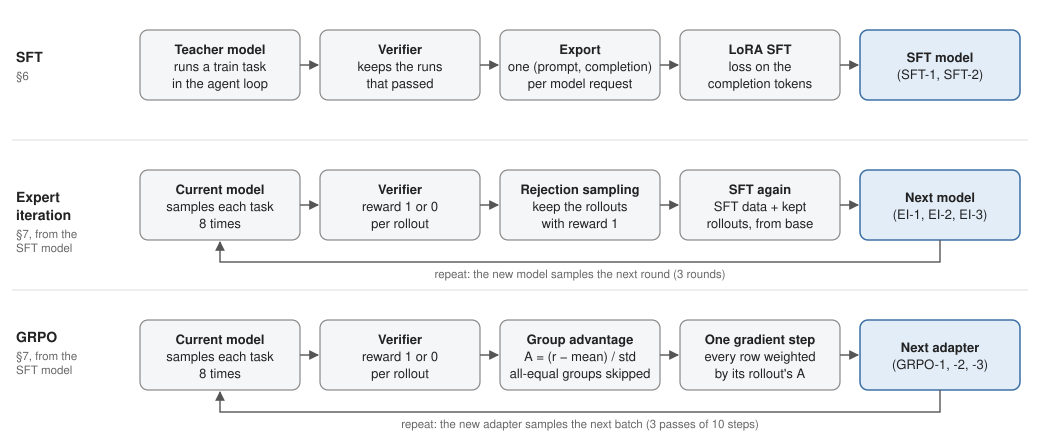

In [10]:
from IPython.display import SVG, display

display(SVG(filename=str(DATA / "post_training.svg")))

## 6. SFT: a teacher's verified run becomes training data

The student is the 4B model. The **teacher** is a stronger model run in the same agent loop, with
the same tools and the same verifier, on train tasks only. Here the teacher is the model chosen in
the first cell (the project used DeepSeek, through `bench --backend teacher`). The task comes from
the generator of §4: a train task in its fault variant, where a read fails once, so a good run
also shows recovery.

In [11]:
from agent_from_scratch.evals.bench.run import run_case

skeleton, ctx = next((s, c) for s, c in specs("train")
                     if s.name == "inventory_reconciliation" and c.condition == "fault")
run_dir = Path(mkdtemp(prefix="walkthrough-teacher-")) / "run"
logger.disable("agent_from_scratch")  # the injected read failure is logged as an error; it is expected
record = run_case(model, skeleton, ctx, run_dir)  # build the workspace, run the loop, verify
logger.enable("agent_from_scratch")
task = json.loads((run_dir / "task.json").read_text())
trace = json.loads(next((run_dir / "state/runs").glob("*.jsonl")).read_text().splitlines()[-1])
show(trace["messages"])
failed = [check for check, ok in record["checks"].items() if ok is False]
print("\npassed:", record["passed"], "| failed checks:", failed or "none")

user      : Read inventory.json and shipment.json. Report the IDs in shipment's ids list that are absent from inventory's ids list. Reply only with the missing ID …
assistant : I'll read both files first.
assistant → read_file({"path": "inventory.json"})
assistant → read_file({"path": "shipment.json"})
tool      ← Tool execution failed. Temporary read failure; retry the read.
tool      ← Tool call was not executed. An earlier call failed. Reconsider these calls using its result before retrying.
assistant : The first read failed with a temporary error; retrying.
assistant → read_file({"path": "inventory.json"})
tool      ← 1| {"source": "inventory", "ids": ["SKU-470", "SKU-295", "SKU-371"]}
assistant → read_file({"path": "shipment.json"})
tool      ← 1| {"source": "shipment", "ids": ["SKU-470"]}
assistant : NONE

passed: True | failed checks: none


**From a run to examples.** Only verified runs become data. `rejection` is the export's gate: a
failed run is refused, and so is a run whose history holds the model's own failed call
(`--flawed-turns drop` keeps the run and leaves out only that turn). The injected fault is not the
model's mistake, so recovering from it is a target. Each model request then becomes one example:
the prompt is exactly what the model saw, rendered with the student's chat template, and the
completion is what the teacher answered.

In [12]:
from agent_from_scratch.config import BENCH_MODEL, CHAT_TEMPLATE_PATH
from agent_from_scratch.evals.sft.export import examples_from_trace, rejection
from agent_from_scratch.llm import compile_chat_template

template = compile_chat_template(CHAT_TEMPLATE_PATH.read_text())
print("refused because:", rejection(record, task, trace, flawed="drop"))
examples = examples_from_trace(trace, template)
print(len(examples), "examples, one per model request\n")
example = examples[1]  # the request right after the failed read
print("prompt (last 500 characters):\n" + example["prompt"][-500:])
print("\ncompletion:\n" + example["completion"])

refused because: None
4 examples, one per model request

prompt (last 500 characters):
"read_file", "ok": false, "output": null, "error_code": "execution_error", "error_message": "Tool execution failed. Temporary read failure; retry the read."}
</tool_response>
<tool_response>
{"call_id": "call_01_ET_eBduTiqtOqbjGzsHqxM92090", "tool_name": "read_file", "ok": false, "output": null, "error_code": "skipped", "error_message": "Tool call was not executed. An earlier call failed. Reconsider these calls using its result before retrying."}
</tool_response><|im_end|>
<|im_start|>assistant


completion:
The first read failed with a temporary error; retrying.
<tool_call>
{"name": "read_file", "arguments": {"path": "inventory.json"}}
</tool_call><|im_end|>


**The loss mask.** The prompt, tool results included, is context; the loss falls on the
completion's tokens only.

In [13]:
import transformers
from agent_from_scratch.evals.sft.tensorize import IGNORE, encode_example
from agent_from_scratch.evals.sft.train import hf_tokenize

tokenizer = transformers.AutoTokenizer.from_pretrained(BENCH_MODEL["id"], revision=BENCH_MODEL["revision"])
row = encode_example({"id": "demo", **example}, hf_tokenize(tokenizer))
targets = sum(label != IGNORE for label in row["labels"])
print(f"{len(row['input_ids'])} tokens; the loss falls on {targets} of them\n")
first = next(i for i, label in enumerate(row["labels"]) if label != IGNORE)
for i in range(first - 6, len(row["input_ids"])):
    piece = tokenizer.decode([row["input_ids"][i]])
    print(f"{i:5}  {'target' if row['labels'][i] != IGNORE else 'masked':6}  {piece!r}")

1088 tokens; the loss falls on 33 of them

 1049  masked  '</tool_response>'
 1050  masked  '<|im_end|>'
 1051  masked  '\n'
 1052  masked  '<|im_start|>'
 1053  masked  'assistant'
 1054  masked  '\n'
 1055  target  'The'
 1056  target  ' first'
 1057  target  ' read'
 1058  target  ' failed'
 1059  target  ' with'
 1060  target  ' a'
 1061  target  ' temporary'
 1062  target  ' error'
 1063  target  ';'
 1064  target  ' retry'
 1065  target  'ing'
 1066  target  '.\n'
 1067  target  '<tool_call>'
 1068  target  '\n'
 1069  target  '{"'
 1070  target  'name'
 1071  target  '":'
 1072  target  ' "'
 1073  target  'read'
 1074  target  '_file'
 1075  target  '",'
 1076  target  ' "'
 1077  target  'arguments'
 1078  target  '":'
 1079  target  ' {"'
 1080  target  'path'
 1081  target  '":'
 1082  target  ' "'
 1083  target  'inventory'
 1084  target  '.json'
 1085  target  '"}}\n'
 1086  target  '</tool_call>'
 1087  target  '<|im_end|>'


**Training.** `train` turns a folder of such examples into a LoRA adapter (the commands are in
`evals/README.md`, "Training an adapter"). The project's SFT-1 trained on 956 teacher examples
from 320 train tasks, repeated three times, plus 5,002 rows of public tool-use data: 7,870 rows,
three epochs on one A100 in 5.3 hours, mean loss by epoch 0.515, 0.368 and 0.291. On the 140
test tasks it raised pass@1 from 0.419 to 0.774.

## 7. Expert iteration and GRPO: learning from the model's own samples

Both methods start from an SFT model and let it sample each train task 8 times. Each rollout
earns the **strict reward**: 1 when the verifier passed it and the answer is exactly the requested
value, else 0.

- **Expert iteration:** keep the rollouts with reward 1 (rejection sampling), add them to the SFT
  data, retrain, and repeat with the new model.
- **GRPO:** use every rollout of a task with mixed outcomes, weighted by its *group advantage*.
  For the $G$ rollouts of one task with rewards $r_i$, mean $\bar r$ and standard deviation $s$:

$$A_i = \frac{r_i - \bar r}{s}, \qquad L(\theta) = -\frac{1}{N}\sum_{i=1}^{N} A_i \cdot \frac{1}{|y_i|}\sum_{t}\log \pi_\theta\left(y_{i,t}\mid x_i,\, y_{i,<t}\right)$$

  A group whose rewards are all equal has $s = 0$ and teaches nothing; it is skipped. With $k$
  passes in $G$ rollouts, a pass gets $A = \sqrt{(G-k)/k}$ and a failure $A = -\sqrt{k/(G-k)}$.

Below are 8 recorded samples of SFT-2, the starting model of both methods, on one leveled train
task: reconcile stock files against a ledger while one read fails in the middle of the scan.

In [14]:
from agent_from_scratch.evals.sft.grpo import advantages, reward, sampled_rows

recorded = json.loads((DATA / "sft2_rollouts.json").read_text())
task, rollouts = recorded["task"], recorded["rollouts"]
print(task["id"], "-", cut(task["prompt"], 400), "\n")
print(f"{'seed':>4}  {'requests':>8}  {'reward':>6}  failed checks")
for r in rollouts:
    failed = [check for check, ok in r["record"]["checks"].items() if ok is False]
    print(f"{r['seed']:>4}  {len(r['trace']['model_requests']):>8}  {reward(r['record']):>6}  {', '.join(failed) or '-'}")

fault_amid_reconcile-6-fault - ledger.csv lists each SKU's expected count, and stock/ holds one counted file per SKU. List stock/, read ledger.csv and every stock file, and write discrepancies.txt with one line per SKU whose counted number differs from the ledger, as SKU: expected N, counted M, sorted by SKU. If a read fails, read that file again. Read discrepancies.txt back and reply only RECONCILED. 

seed  requests  reward  failed checks
   0         5       0  files, format_exact
   1         7       0  files
   2         6       1  -
   3         6       0  files
   4         5       0  files, format_exact
   5         5       0  files, format_exact
   6         5       0  files, format_exact
   7         6       1  -


**Expert iteration** keeps the rollouts with reward 1 that pass the same gate as the teacher's,
at most one per task (`--max-per-task 1`), and exports them exactly as §6 exported the teacher's
run. The round's training data is SFT-2's data plus these examples, and the next model is trained
from the base on it. A round in this project kept about 300 examples from the 80 leveled tasks,
about 3% of its rows.

In [15]:
kept = [r for r in rollouts
        if reward(r["record"]) and rejection(r["record"], task, r["trace"], flawed="drop") is None]
print(f"kept {len(kept)} of {len(rollouts)} rollouts (seeds {[r['seed'] for r in kept]})")
chosen = kept[0]
own = examples_from_trace(chosen["trace"], template)
print(f"seed {chosen['seed']} becomes {len(own)} SFT examples; its final answer:\n" + own[-1]["completion"])

kept 2 of 8 rollouts (seeds [2, 7])
seed 2 becomes 6 SFT examples; its final answer:
RECONCILED<|im_end|>


**GRPO** uses all 8 rollouts. Each rollout's advantage becomes the weight of every request it
made. A row's completion is the text as sampled, not a clean re-rendering, because the gradient
must be taken on the tokens the model produced.

In [16]:
rewards = [reward(r["record"]) for r in rollouts]
weights = advantages(rewards)
print(f"{'seed':>4}  {'reward':>6}  {'advantage':>9}  {'rows':>4}")
rows = 0
for r, earned, weight in zip(rollouts, rewards, weights):
    count = len(sampled_rows(r["trace"], template))
    rows += count
    print(f"{r['seed']:>4}  {earned:>6}  {weight:>+9.2f}  {count:>4}")
print(f"\n{rows} rows: the two passing rollouts' requests are pushed up, the six failing ones down")

seed  reward  advantage  rows
   0       0      -0.58     5
   1       0      -0.58     7
   2       1      +1.73     6
   3       0      -0.58     6
   4       0      -0.58     5
   5       0      -0.58     5
   6       0      -0.58     5
   7       1      +1.73     6

45 rows: the two passing rollouts' requests are pushed up, the six failing ones down


One task is one group. A GRPO step samples 8 tasks, 8 times each; here are all the groups of the
first step, with their rewards:

In [17]:
from agent_from_scratch.evals.sft.grpo import advantages, reward

recorded = json.loads((DATA / "stage10_grpo_group.json").read_text())
groups = {}
for rollout in recorded["rollouts"]:
    groups.setdefault(rollout["id"], []).append(reward(rollout))
print(f"{'task':30} rewards (seeds 0-7)   advantages")
for task_id, rewards in groups.items():
    a = advantages(rewards)
    print(f"{task_id:30} {rewards}  {'skipped' if a is None else [round(x, 2) for x in a]}")
mixed = sum(advantages(r) is not None for r in groups.values())
mean = sum(map(sum, groups.values())) / len(recorded["rollouts"])
print(f"\nmixed groups {mixed} of {len(groups)}, mean reward {mean:.4f}; the step recorded:",
      {k: recorded["step_groups"][k] for k in ("mixed", "all_pass", "all_fail", "mean_reward")})

task                           rewards (seeds 0-7)   advantages
ordered_migration-7            [1, 0, 0, 1, 1, 1, 1, 1]  [0.58, -1.73, -1.73, 0.58, 0.58, 0.58, 0.58, 0.58]
ordered_migration-11           [1, 1, 1, 1, 1, 1, 1, 1]  skipped
rule_table_apply-3             [1, 1, 1, 1, 1, 1, 1, 1]  skipped
rule_table_apply-4             [0, 1, 0, 1, 1, 1, 1, 1]  [-1.73, 0.58, -1.73, 0.58, 0.58, 0.58, 0.58, 0.58]
long_edit_dialogue-8           [0, 0, 0, 0, 0, 0, 0, 0]  skipped
long_edit_dialogue-13          [1, 1, 1, 1, 1, 1, 1, 1]  skipped
fault_amid_reconcile-6-fault   [0, 0, 1, 0, 0, 0, 0, 1]  [-0.58, -0.58, 1.73, -0.58, -0.58, -0.58, -0.58, 1.73]
fault_amid_reconcile-7-clean   [0, 0, 0, 0, 0, 0, 0, 0]  skipped

mixed groups 3 of 8, mean reward 0.5938; the step recorded: {'mixed': 3, 'all_pass': 3, 'all_fail': 2, 'mean_reward': 0.5938}


Only 3 of the 8 tasks gave a gradient in this step: each update rested on a handful of tasks.
Below, the two methods on val (144 tasks, three samples each, every model on one server),
recomputed from the recorded runs: EI-1 to EI-3 are three rounds of expert iteration, and GRPO-1
to GRPO-3 used the same number of rollouts.

In [18]:
from IPython.display import Markdown
from agent_from_scratch.evals import report

LABELS = {"m1": "SFT-2 (start)", "m2": "EI-1", "m3": "EI-2", "m4": "EI-3",
          "grpo1": "GRPO-1", "grpo2": "GRPO-2", "grpo3": "GRPO-3"}
recorded_runs = json.loads((DATA / "stage10_val_runs.json").read_text())["arms"]
arms = {LABELS[name]: runs for name, runs in recorded_runs.items()}  # each: three runs, one per seed
leveled = {"flag_rollout", "itinerary_dialogue"}
every_type = {r["skeleton"] for run in arms["SFT-2 (start)"] for r in run}
subsets = {"Val (144)": None, "Single- and multi-turn (104)": every_type - leveled, "Leveled (40)": leveled}
display(Markdown(report.table(arms, subsets)))
display(Markdown(report.pair_table(arms, [("SFT-2 (start)", "EI-3"), ("SFT-2 (start)", "GRPO-3")],
                                   {"Val": None, "Leveled": leveled})))

| Arm | Val (144) | Single- and multi-turn (104) | Leveled (40) | Passed by seed |
|---|---:|---:|---:|---|
| SFT-2 (start) | 0.752 (144) | 0.955 (104) | 0.225 (40) | 113, 106, 106 |
| EI-1 | 0.785 (144) | 0.907 (104) | 0.467 (40) | 113, 113, 113 |
| EI-2 | 0.729 (144) | 0.856 (104) | 0.400 (40) | 104, 107, 104 |
| EI-3 | 0.852 (144) | 0.942 (104) | 0.617 (40) | 124, 117, 127 |
| GRPO-1 | 0.718 (144) | 0.891 (104) | 0.267 (40) | 109, 95, 106 |
| GRPO-2 | 0.722 (144) | 0.885 (104) | 0.300 (40) | 107, 98, 107 |
| GRPO-3 | 0.731 (144) | 0.875 (104) | 0.358 (40) | 112, 99, 105 |


| B against A | Subset | Pairs | B wins | B loses | McNemar p | B − A, 95% interval |
|---|---|---:|---:|---:|---:|---|
| EI-3 vs SFT-2 (start) | Val | 432 | 67 | 24 | 0.0000 | +0.100 [+0.042, +0.160] |
| EI-3 vs SFT-2 (start) | Leveled | 120 | 57 | 10 | 0.0000 | +0.392 [+0.233, +0.542] |
| GRPO-3 vs SFT-2 (start) | Val | 432 | 39 | 48 | 0.3912 | -0.021 [-0.074, +0.032] |
| GRPO-3 vs SFT-2 (start) | Leveled | 120 | 31 | 15 | 0.0259 | +0.133 [+0.008, +0.258] |


At every equal amount of sampling, expert iteration beat GRPO on val, and EI-3 was the best:
0.852 against SFT-2's 0.752, the leveled 40 from 0.225 to 0.617. The rounds were not monotone, so
part of that is likely retraining variance. On the held-out test and hard test, run once after
this choice, EI-3 is level with SFT-2 and SFT-1 overall, and the most balanced of the three:
second on both held-out sets and first on BFCL multi-turn. `docs/results.md` has the tables.